In [4]:
# Import các thư viện cần thiết
import warnings
warnings.filterwarnings('ignore') # Ẩn bớt các cảnh báo DeprecationWarning

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

from mlxtend.frequent_patterns import apriori, association_rules

# Đọc tập tin dữ liệu Online Retail
df = pd.read_excel('Online Retail.xlsx')

# In thông tin sinh viên ngay trên bảng kết quả
print("Họ và tên: Vũ Trương Phi")
print("MSSV: 6451071059")
print("-" * 40)

# Xem thông tin dữ liệu
df.info()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Họ và tên: Vũ Trương Phi
MSSV: 6451071059
----------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [5]:
# Cắt bỏ ký tự thừa ở tên mặt hàng (Description)
df['Description'] = df['Description'].str.strip()

# Xóa các dòng không có số hóa đơn (InvoiceNo)
df.dropna(axis=0, subset=['InvoiceNo'], inplace=True)

# Chuyển cột InvoiceNo về kiểu chuỗi (string)
df['InvoiceNo'] = df['InvoiceNo'].astype('str')

# In thông tin sinh viên ngay trên bảng kết quả
print("Họ và tên: Vũ Trương Phi")
print("MSSV: 6451071059")
print("-" * 40)

# Xem 10 dòng đầu của dữ liệu sau khi làm sạch
df.head(10)

Họ và tên: Vũ Trương Phi
MSSV: 6451071059
----------------------------------------


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom


In [6]:
# In thông tin sinh viên
print("Họ và tên: Vũ Trương Phi")
print("MSSV: 6451071059")
print("-" * 40)

# Xem ví dụ về các hóa đơn tín dụng (chứa ký tự 'C' trong InvoiceNo)
print("Ví dụ về hóa đơn tín dụng:")
display(df[df.InvoiceNo.str.contains('C', na=False)].head())

# Tiến hành xóa các hóa đơn tín dụng (chỉ giữ lại hóa đơn không chứa 'C')
df = df[~df['InvoiceNo'].str.contains('C')]

Họ và tên: Vũ Trương Phi
MSSV: 6451071059
----------------------------------------
Ví dụ về hóa đơn tín dụng:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


Họ và tên: Vũ Trương Phi
MSSV: 6451071059
----------------------------------------


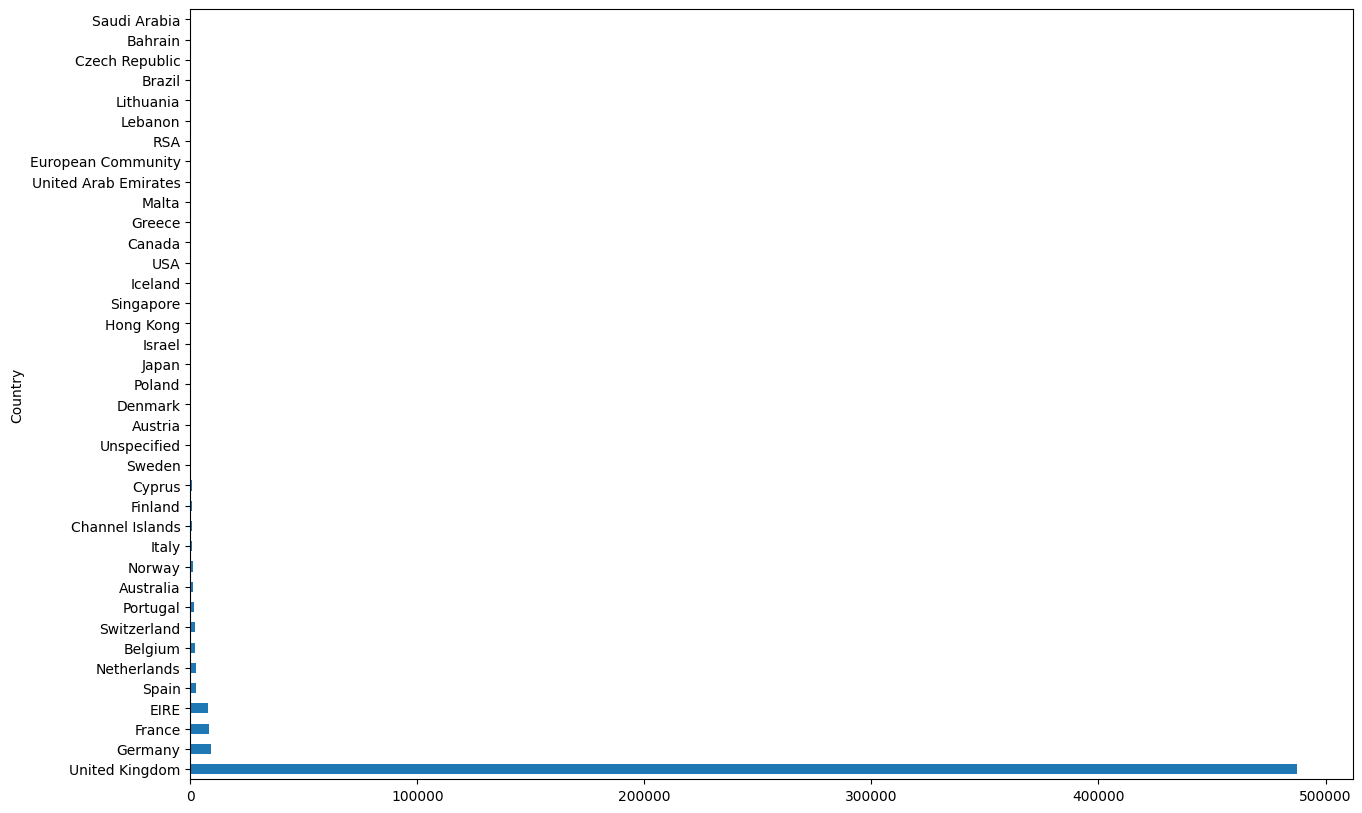

In [7]:
# In thông tin sinh viên
print("Họ và tên: Vũ Trương Phi")
print("MSSV: 6451071059")
print("-" * 40)

# Vẽ biểu đồ thanh ngang thống kê số lượng dòng dữ liệu theo từng quốc gia
plt.figure(figsize=(15, 10))
df['Country'].value_counts().plot(kind='barh', figsize=(15, 10))
plt.show()

In [8]:
# In thông tin sinh viên
print("Họ và tên: Vũ Trương Phi")
print("MSSV: 6451071059")
print("-" * 40)

# Lọc hóa đơn từ United Kingdom và gom nhóm theo InvoiceNo, Description đối với cột Quantity
basket = df[df['Country'] == "United Kingdom"].groupby(['InvoiceNo', 'Description'])['Quantity']

# Hiển thị vài dòng để kiểm tra kết quả
basket.sum().head(10)

Họ và tên: Vũ Trương Phi
MSSV: 6451071059
----------------------------------------


InvoiceNo  Description                        
536365     CREAM CUPID HEARTS COAT HANGER          8
           GLASS STAR FROSTED T-LIGHT HOLDER       6
           KNITTED UNION FLAG HOT WATER BOTTLE     6
           RED WOOLLY HOTTIE WHITE HEART.          6
           SET 7 BABUSHKA NESTING BOXES            2
           WHITE HANGING HEART T-LIGHT HOLDER      6
           WHITE METAL LANTERN                     6
536366     HAND WARMER RED POLKA DOT               6
           HAND WARMER UNION JACK                  6
536367     ASSORTED COLOUR BIRD ORNAMENT          32
Name: Quantity, dtype: int64

In [9]:
# Chuyển đổi dữ liệu về dạng bảng chéo (mỗi dòng là 1 hóa đơn, cột là tên sản phẩm)
basket = basket.sum().unstack().reset_index().fillna(0).set_index('InvoiceNo')

# In thông tin sinh viên ngay trên bảng kết quả
print("Họ và tên: Vũ Trương Phi")
print("MSSV: 6451071059")
print("-" * 40)

# Xem 10 dòng đầu của dữ liệu
basket.head(10)

Họ và tên: Vũ Trương Phi
MSSV: 6451071059
----------------------------------------


Description,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD,12 HANGING EGGS HAND PAINTED,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,...,wrongly coded 20713,wrongly coded 23343,wrongly coded-23343,wrongly marked,wrongly marked 23343,wrongly marked carton 22804,wrongly marked. 23343 in box,wrongly sold (22719) barcode,wrongly sold as sets,wrongly sold sets
InvoiceNo,,,,,,,,,,,,,,,,,,,,,
536365,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536366,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536367,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536368,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536369,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536371,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536372,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536373,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536374,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [10]:
# Tạo hàm biến đổi: giá trị <= 0 thành 0, >= 1 thành 1
def encode_data(datapoint):
    if datapoint <= 0:
        return 0
    if datapoint >= 1:
        return 1

# Áp dụng hàm biến đổi cho toàn bộ DataFrame
basket = basket.applymap(encode_data)

# In thông tin sinh viên ngay trên bảng kết quả
print("Họ và tên: Vũ Trương Phi")
print("MSSV: 6451071059")
print("-" * 40)

# Xem 10 dòng đầu sau khi chuyển thành one-hot encoding
basket.head(10)

Họ và tên: Vũ Trương Phi
MSSV: 6451071059
----------------------------------------


Description,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD,12 HANGING EGGS HAND PAINTED,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,...,wrongly coded 20713,wrongly coded 23343,wrongly coded-23343,wrongly marked,wrongly marked 23343,wrongly marked carton 22804,wrongly marked. 23343 in box,wrongly sold (22719) barcode,wrongly sold as sets,wrongly sold sets
InvoiceNo,,,,,,,,,,,,,,,,,,,,,
536365,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536366,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536367,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536368,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536369,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536371,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536372,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536373,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536374,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [11]:
# In thông tin sinh viên
print("Họ và tên: Vũ Trương Phi")
print("MSSV: 6451071059")
print("-" * 40)

# Xóa cột POSTAGE nếu có tồn tại
basket.drop('POSTAGE', inplace=True, axis=1)

print("Đã xóa cột 'POSTAGE' thành công!")

Họ và tên: Vũ Trương Phi
MSSV: 6451071059
----------------------------------------
Đã xóa cột 'POSTAGE' thành công!


In [12]:
# Áp dụng thuật toán Apriori với min_support = 0.03 (3%)
itemsets = apriori(basket, min_support=0.03, use_colnames=True)

# In thông tin sinh viên ngay trên bảng kết quả
print("Họ và tên: Vũ Trương Phi")
print("MSSV: 6451071059")
print("-" * 40)

# Xem 10 phần tử đầu tiên trong tập phổ biến tìm được
itemsets.head(10)

Họ và tên: Vũ Trương Phi
MSSV: 6451071059
----------------------------------------


,support,itemsets
0,0.045803,(6 RIBBONS RUSTIC CHARM)
1,0.031124,(60 CAKE CASES VINTAGE CHRISTMAS)
2,0.040339,(60 TEATIME FAIRY CAKE CASES)
3,0.046928,(ALARM CLOCK BAKELIKE GREEN)
4,0.035142,(ALARM CLOCK BAKELIKE PINK)
5,0.049821,(ALARM CLOCK BAKELIKE RED)
6,0.036214,(ANTIQUE SILVER T-LIGHT GLASS)
7,0.073445,(ASSORTED COLOUR BIRD ORNAMENT)
8,0.042267,(BAKING SET 9 PIECE RETROSPOT)
9,0.035089,(BATHROOM METAL SIGN)


In [13]:
# In thông tin sinh viên
print("Họ và tên: Vũ Trương Phi")
print("MSSV: 6451071059")
print("-" * 40)

# 1. Tạo tập luật kết hợp với độ tin cậy tối thiểu (confidence) >= 0.5 (50%)
rules = association_rules(itemsets, metric="confidence", min_threshold=0.5)

# Hiển thị thông tin tổng quan của tập luật
rules.info()
print("-" * 40)

# 2. Chuyển đổi vế trái (antecedents) và vế phải (consequents) từ frozenset về kiểu chuỗi
rules["antecedents"] = rules["antecedents"].apply(lambda x: list(x)[0]).astype("unicode")
rules["consequents"] = rules["consequents"].apply(lambda x: list(x)[0]).astype("unicode")

# 3. In chi tiết từng luật kết hợp tìm được
for i in range(len(rules)):
    print(rules.loc[i, 'antecedents'], '==>', rules.loc[i, 'consequents'],
          '[', rules.loc[i, 'support'], ',', rules.loc[i, 'confidence'], ']')

Họ và tên: Vũ Trương Phi
MSSV: 6451071059
----------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   antecedents         10 non-null     object 
 1   consequents         10 non-null     object 
 2   antecedent support  10 non-null     float64
 3   consequent support  10 non-null     float64
 4   support             10 non-null     float64
 5   confidence          10 non-null     float64
 6   lift                10 non-null     float64
 7   representativity    10 non-null     float64
 8   leverage            10 non-null     float64
 9   conviction          10 non-null     float64
 10  zhangs_metric       10 non-null     float64
 11  jaccard             10 non-null     float64
 12  certainty           10 non-null     float64
 13  kulczynski          10 non-null     float64
dtypes: float64(12), object(2)


Họ và tên: Vũ Trương Phi
MSSV: 6451071059
----------------------------------------


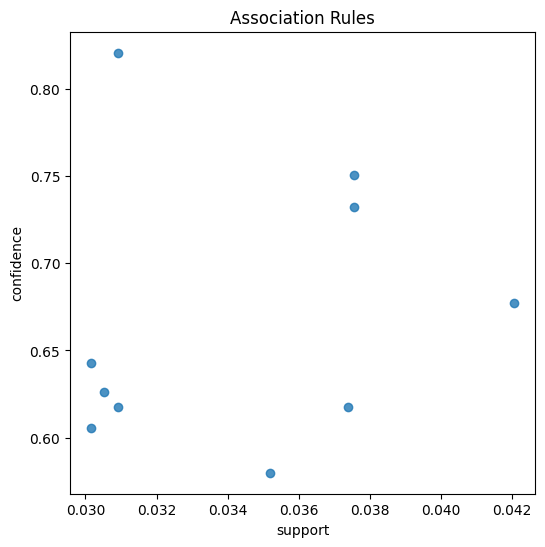

In [14]:
# In thông tin sinh viên
print("Họ và tên: Vũ Trương Phi")
print("MSSV: 6451071059")
print("-" * 40)

# Lấy giá trị độ hỗ trợ (support) và độ tin cậy (confidence)
support = rules['support'].values
confidence = rules['confidence'].values

# Vẽ biểu đồ phân tán
plt.figure(figsize=(6, 6))
plt.title('Association Rules')
plt.xlabel('support')
plt.ylabel('confidence')
sns.regplot(x=support, y=confidence, fit_reg=False)
plt.show()

In [15]:
# In thông tin sinh viên
print("Họ và tên: Vũ Trương Phi")
print("MSSV: 6451071059")
print("-" * 40)

# 1. Import thuật toán fpgrowth từ mlxtend
from mlxtend.frequent_patterns import fpgrowth

# 2. Tìm tập phổ biến với min_support = 3%
itemsets_fp = fpgrowth(basket, min_support=0.03, use_colnames=True)

print("10 tập mục phổ biến đầu tiên theo FP-Growth:")
display(itemsets_fp.head(10))
print("-" * 40)

# 3. Tạo tập luật kết hợp từ FP-Growth với min_conf = 50%
rules_fp = association_rules(itemsets_fp, metric="confidence", min_threshold=0.5)

# Chuyển đổi vế trái và vế phải về dạng chuỗi
rules_fp["antecedents"] = rules_fp["antecedents"].apply(lambda x: list(x)[0]).astype("unicode")
rules_fp["consequents"] = rules_fp["consequents"].apply(lambda x: list(x)[0]).astype("unicode")

print("Các luật kết hợp tìm được từ FP-Growth:")
for i in range(len(rules_fp)):
    print(rules_fp.loc[i, 'antecedents'], '==>', rules_fp.loc[i, 'consequents'],
          '[', rules_fp.loc[i, 'support'], ',', rules_fp.loc[i, 'confidence'], ']')
print("-" * 40)

# 4. So sánh số lượng kết quả giữa Apriori và FP-Growth
print(f"Số tập phổ biến (Apriori): {len(itemsets)} | (FP-Growth): {len(itemsets_fp)}")
print(f"Số luật sinh ra (Apriori): {len(rules)} | (FP-Growth): {len(rules_fp)}")

Họ và tên: Vũ Trương Phi
MSSV: 6451071059
----------------------------------------
10 tập mục phổ biến đầu tiên theo FP-Growth:


,support,itemsets
0,0.116034,(WHITE HANGING HEART T-LIGHT HOLDER)
1,0.073445,(ASSORTED COLOUR BIRD ORNAMENT)
2,0.040071,(HOME BUILDING BLOCK WORD)
3,0.032517,(LOVE BUILDING BLOCK WORD)
4,0.030107,(DOORMAT NEW ENGLAND)
5,0.053517,(JAM MAKING SET WITH JARS)
6,0.060267,(PAPER CHAIN KIT 50'S CHRISTMAS)
7,0.057642,(WOODEN PICTURE FRAME WHITE FINISH)
8,0.050463,(WOODEN FRAME ANTIQUE WHITE)
9,0.037714,(RED HANGING HEART T-LIGHT HOLDER)


----------------------------------------
Các luật kết hợp tìm được từ FP-Growth:
JUMBO BAG PINK POLKADOT ==> JUMBO BAG RED RETROSPOT [ 0.042052820485348474 , 0.6773080241587576 ]
JUMBO STORAGE BAG SUKI ==> JUMBO BAG RED RETROSPOT [ 0.037392189425188835 , 0.6176991150442478 ]
JUMBO  BAG BAROQUE BLACK WHITE ==> JUMBO BAG RED RETROSPOT [ 0.03053516901483902 , 0.6263736263736264 ]
JUMBO SHOPPER VINTAGE RED PAISLEY ==> JUMBO BAG RED RETROSPOT [ 0.03519580007499866 , 0.5798764342453663 ]
ALARM CLOCK BAKELIKE GREEN ==> ALARM CLOCK BAKELIKE RED [ 0.030160175711148016 , 0.6426940639269406 ]
ALARM CLOCK BAKELIKE RED ==> ALARM CLOCK BAKELIKE GREEN [ 0.030160175711148016 , 0.6053763440860216 ]
GREEN REGENCY TEACUP AND SAUCER ==> ROSES REGENCY TEACUP AND SAUCER [ 0.03755290084105641 , 0.7505353319057816 ]
ROSES REGENCY TEACUP AND SAUCER ==> GREEN REGENCY TEACUP AND SAUCER [ 0.03755290084105641 , 0.7324973876698014 ]
GREEN REGENCY TEACUP AND SAUCER ==> PINK REGENCY TEACUP AND SAUCER [ 0.030910162318